# File 1: Data Exploration & Quality (Auckland)

## Purpose
Check the cleaned SA2 dataset before any analysis or dashboard work. Find where the data can be trusted,
where it misleads, and flag the SA2s that should be excluded or labelled on the dashboard.

## Why this comes before analysis
Data collection and cleaning live in scripts (`download_data.py`, `build_master.py`) so they can be re-run when
sources republish. This notebook is where we first *look* at the result. Three problems are already known:
- **Capital values (CVs) include commercial property.** The source has no property-type field, so some SA2 medians reach $31m.
- **Crime rates are per resident.** Shopping centres and industrial areas have few residents and many visitors.
- **Rent is missing or borrowed** for some SA2s (MBIE uses 2018 SA2 codes).

## Data
| File | Rows | What |
|---|---|---|
| `data/clean/master_dataset_by_sa2.csv` | 633 SA2s | Census 2023, CV 2021 & 2024, rent, yield, crime, amenities |
| `data/clean/rent_timeseries_by_sa2.csv` | ~73,500 | Quarterly median rent and active bonds by SA2, 1993–2026 |
| `data/boundaries/auckland_sa2_2023.geojson` | 633 | SA2 polygons for maps |

## Steps
1. Load data and check coverage
2. Capital values: distribution and commercial outliers
3. Build data-quality flags
4. CV change 2021 → 2024
5. Rent: Auckland trend and SA2 spread
6. Gross rental yield
7. Crime rates with and without flagged SA2s
8. How the measures relate (correlation)
9. Save outputs

## Outputs
- `data/clean/master_flagged.csv`: the master file plus flag columns, used by later notebooks and the dashboard
- `visualizations/01_*.png`: charts from this notebook

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)

# Palette: categorical slots 1-2, single-hue sequential, orange-grey-blue diverging
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
SEQ = 'Blues'
DIV = LinearSegmentedColormap.from_list('div', [ORANGE, '#e6e5e1', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
dollars = FuncFormatter(lambda v, _: f'${v/1e6:.1f}m' if v >= 1e6 else f'${v/1e3:.0f}k')
CV_TICKS = [1e5, 3e5, 5e5, 1e6, 2e6, 5e6, 1e7, 3e7]

def cv_axis(ax, lo, hi):
    ax.set_xscale('log'); ax.set_xticks([t for t in CV_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(dollars); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.width', 160, 'display.max_columns', 40)

### Step 1: Load data and check coverage

In [2]:
# STEP 1: LOAD DATA AND CHECK COVERAGE
m = pd.read_csv(CLEAN / 'master_dataset_by_sa2.csv')
rent_ts = pd.read_csv(CLEAN / 'rent_timeseries_by_sa2.csv', parse_dates=['quarter'])
geo = gpd.read_file('data/boundaries/auckland_sa2_2023.geojson')
geo['sa2_code'] = geo['SA22023_V1_00'].astype(int)

assert m['sa2_code'].is_unique and len(m) == 633
print(f'Master: {m.shape[0]} SA2s x {m.shape[1]} columns | rent series: {len(rent_ts):,} rows | polygons: {len(geo)}')
print(f'Residents covered: {m.population_2023.sum():,.0f}')

key = ['population_2023', 'median_household_income', 'median_cv_2024', 'median_rent_weekly',
       'gross_yield_pct', 'rent_change_5y_pct', 'crime_per_1000_residents', 'pct_owner_occupied']
coverage = pd.DataFrame({'SA2s with value': m[key].notna().sum(),
                         '% of SA2s': (100 * m[key].notna().mean()).round(1),
                         '% of residents': [round(100 * m.loc[m[k].notna(), 'population_2023'].sum()
                                                  / m.population_2023.sum(), 1) for k in key]})
coverage

Master: 633 SA2s x 56 columns | rent series: 73,523 rows | polygons: 633
Residents covered: 1,656,417


,SA2s with value,% of SA2s,% of residents
population_2023,627,99.1,100.0
median_household_income,620,97.9,100.0
median_cv_2024,633,100.0,100.0
median_rent_weekly,600,94.8,99.1
gross_yield_pct,600,94.8,99.1
rent_change_5y_pct,593,93.7,98.6
crime_per_1000_residents,619,97.8,100.0
pct_owner_occupied,618,97.6,100.0


### Step 2: Capital values, distribution and commercial outliers

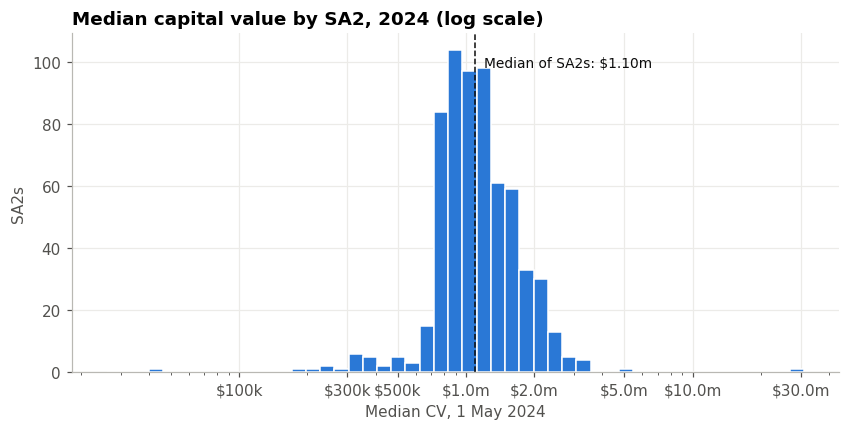

Highest median CVs: note the industrial and near-empty SA2s mixed in with Remuera and Herne Bay


,sa2_name,population_2023,dwellings_2023,rating_units,units_per_dwelling,median_cv_2024
481,Middlemore,138.0,3.0,5,1.67,31000000.0
102,Mount Wellington Industrial,9.0,6.0,431,71.83,5050000.0
600,Botany Central,6.0,3.0,36,12.00,3437500.0
157,Remuera Waitaramoa,3828.0,1536.0,1578,1.03,3275000.0
376,Herne Bay,2775.0,1401.0,1253,0.89,3225000.0
341,Remuera Waiata,2865.0,1164.0,1142,0.98,3200000.0
48,Coatesville,2112.0,807.0,848,1.05,2862500.0
373,Takanini Industrial,27.0,6.0,167,27.83,2850000.0
49,Dairy Flat North,1797.0,603.0,600,1.00,2775000.0
45,Auckland Airport,528.0,183.0,695,3.80,2725000.0


In [3]:
# STEP 2: CAPITAL VALUES - DISTRIBUTION AND OUTLIERS
m['units_per_dwelling'] = m.rating_units / m.dwellings_2023.replace(0, np.nan)

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(np.log10(m.median_cv_2024.min()), np.log10(m.median_cv_2024.max()), 50)
ax.hist(m.median_cv_2024, bins=bins, color=BLUE, edgecolor='white', linewidth=1)
cv_axis(ax, m.median_cv_2024.min(), m.median_cv_2024.max())
ax.axvline(m.median_cv_2024.median(), color=INK, lw=1, ls='--')
ax.annotate(rf'Median of SA2s: \${m.median_cv_2024.median()/1e6:.2f}m', (m.median_cv_2024.median(), ax.get_ylim()[1]*0.9),
            xytext=(6, 0), textcoords='offset points', color=INK, fontsize=9)
ax.set(title='Median capital value by SA2, 2024 (log scale)', xlabel='Median CV, 1 May 2024', ylabel='SA2s')
fig.savefig(VIZ / '01_cv_distribution.png'); plt.show()

cols = ['sa2_name', 'population_2023', 'dwellings_2023', 'rating_units', 'units_per_dwelling', 'median_cv_2024']
print('Highest median CVs: note the industrial and near-empty SA2s mixed in with Remuera and Herne Bay')
m.sort_values('median_cv_2024', ascending=False)[cols].head(12).round(2)

**Reading this:** most SA2s sit between about $0.8m and $1.6m. The tail mixes genuine premium suburbs
(Remuera, Herne Bay) with places that are not housing markets at all (Middlemore hospital land, Mount
Wellington Industrial). The `units_per_dwelling` column separates them: residential areas have about one
rating unit per dwelling, and industrial or commercial areas have many units and few homes.

In [4]:
print(m.units_per_dwelling.describe(percentiles=[.5, .9, .95, .98]).round(2))
for t in [1.5, 2, 3]:
    print(f'SA2s with more than {t} rating units per dwelling: {(m.units_per_dwelling > t).sum()}')
m.sort_values('units_per_dwelling', ascending=False)[cols].head(25).round(2)

count    626.00
mean       1.86
std        9.24
min        0.38
50%        0.98
90%        1.23
95%        1.68
98%        4.69
max      171.00
Name: units_per_dwelling, dtype: float64
SA2s with more than 1.5 rating units per dwelling: 39
SA2s with more than 2 rating units per dwelling: 26
SA2s with more than 3 rating units per dwelling: 19


,sa2_name,population_2023,dwellings_2023,rating_units,units_per_dwelling,median_cv_2024
124,Rosebank Peninsula,9.0,3.0,513,171.00,2025000.0
141,Westgate Central,15.0,3.0,388,129.33,1162500.0
102,Mount Wellington Industrial,9.0,6.0,431,71.83,5050000.0
144,Ōtāhuhu Industrial,153.0,3.0,126,42.00,1550000.0
373,Takanini Industrial,27.0,6.0,167,27.83,2850000.0
118,Wairau Valley,120.0,51.0,1236,24.24,1400000.0
69,East Tamaki,270.0,120.0,1722,14.35,1575000.0
600,Botany Central,6.0,3.0,36,12.00,3437500.0
136,Panmure Glen Innes Industrial,264.0,66.0,628,9.52,1250000.0
121,Botany Junction,105.0,54.0,470,8.70,980000.0


### Step 3: Build data-quality flags
Rules (deliberately simple so they can be explained on the dashboard):
| Flag | Rule | Why |
|---|---|---|
| `flag_low_population` | fewer than 100 residents (or no census count) | per-resident rates and medians are meaningless |
| `flag_non_residential` | more than 2 rating units per dwelling, or fewer than 30 dwellings | CV median is driven by commercial, industrial or institutional property |
| `flag_borrowed_rent` | rent figure identical to another SA2 | inherited from the 2018 parent SA2 |
| `flag_crime_hotspot` | more than 300 victimisations per 1,000 residents (about 10x the median) | town centres and malls: crime follows visitors, not residents |

`analysis_ready` is true when an SA2 has neither of the first two flags. Borrowed rent and crime hotspot are labels:
the CV and rent figures there are fine, but the rent is shared or the crime rate is not comparable.

In [5]:
# STEP 3: DATA-QUALITY FLAGS
m['flag_low_population'] = m.population_2023.fillna(0) < 100
m['flag_non_residential'] = (m.units_per_dwelling > 2) | (m.dwellings_2023.fillna(0) < 30)
# shared rent = another SA2 takes its rent from the same MBIE (2018) source SA2, so both carry one rent figure and bond count
m['flag_borrowed_rent'] = m.median_rent_weekly.notna() & m.duplicated('rent_source_sa2', keep=False)
m['flag_crime_hotspot'] = m.crime_per_1000_residents > 300
m['analysis_ready'] = ~(m.flag_low_population | m.flag_non_residential)

flags = ['flag_low_population', 'flag_non_residential', 'flag_borrowed_rent', 'flag_crime_hotspot', 'analysis_ready']
print(m[flags].sum().to_string())
ready = m[m.analysis_ready]
print(f'\nAnalysis-ready: {len(ready)} SA2s holding {100*ready.population_2023.sum()/m.population_2023.sum():.1f}% of residents')
print('Non-residential SA2s:', ', '.join(m.loc[m.flag_non_residential, 'sa2_name']))
print('Crime hotspots (kept, labelled):', ', '.join(m.loc[m.flag_crime_hotspot & m.analysis_ready, 'sa2_name']))

flag_low_population      14
flag_non_residential     34
flag_borrowed_rent      142
flag_crime_hotspot       27
analysis_ready          599

Analysis-ready: 599 SA2s holding 99.3% of residents
Non-residential SA2s: Oceanic Auckland Region East, Oceanic Auckland Region West, Inlet Kaipara Harbour South, Inlet Manukau Harbour, Inlets other Auckland, Inlet Waitemata Harbour, Riverhead Forest, Bays Waiheke Island, Auckland Airport, Wiri West, East Tamaki, Penrose, North Harbour, Silverdale Central (Auckland), Mount Wellington Industrial, Pukekohe Central, Onehunga-Te Papapa Industrial, Wairau Valley, Botany Junction, Rosebank Peninsula, Panmure Glen Innes Industrial, Henderson Lincoln East, Westgate Central, Ōtāhuhu Industrial, Papakura Industrial, Ōtāhuhu Central, New Lynn Central, Takanini Industrial, Middlemore, Wynyard-Viaduct, Wesley South, Panmure West, Botany Central, Grafton West
Crime hotspots (kept, labelled): Manukau Central, Albany Central, Henderson Central, Papakura Central, 

### Step 4: CV change 2021 → 2024

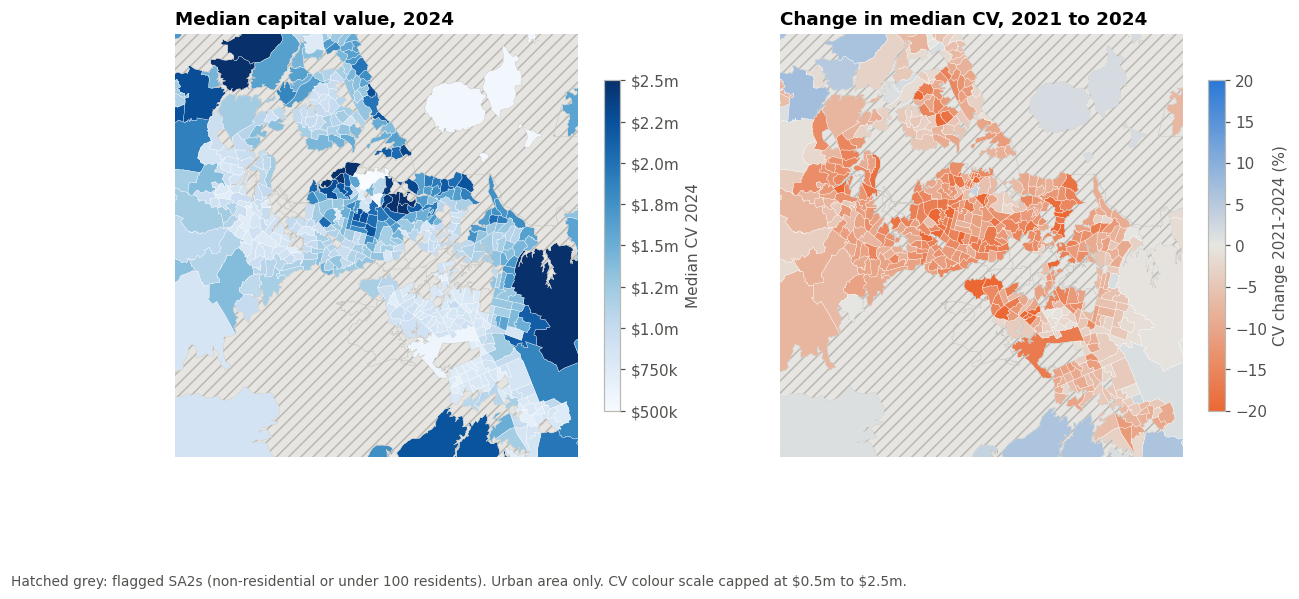

Median SA2 CV change 2021-2024 (analysis-ready): -8.6%
SA2s where CV rose: 56 of 599


,sa2_name,median_cv_2021,median_cv_2024,cv_change_2021_2024_pct
611,Auckland-University,320000.0,210000.0,-34.4
514,Mount Wellington South East,1100000.0,800000.0,-27.3
163,Māngere Bridge,1500000.0,1100000.0,-26.7
616,Massey Road South,1050000.0,790000.0,-24.8
105,Māngere Bridge Ambury,1550000.0,1175000.0,-24.2
532,Māngere East,1175000.0,900000.0,-23.4
398,Newmarket,690000.0,530000.0,-23.2
630,College Hill,790000.0,620000.0,-21.5
6,Barrier Islands,460000.0,630000.0,37.0
31,Tawharanui Peninsula,2125000.0,2375000.0,11.8


In [6]:
# STEP 4: CV CHANGE 2021 -> 2024 (map)
g = geo[['sa2_code', 'geometry']].merge(m, on='sa2_code')
urban = g   # whole region drawn, then the axes are zoomed to the urban area

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
ok, bad = urban[urban.analysis_ready], urban[~urban.analysis_ready]
ok.plot(column='median_cv_2024', cmap=SEQ, vmin=5e5, vmax=2.5e6, ax=axes[0], edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'Median CV 2024', 'shrink': 0.6, 'format': dollars})
lim = 20
ok.plot(column='cv_change_2021_2024_pct', cmap=DIV, vmin=-lim, vmax=lim, ax=axes[1], edgecolor='white', linewidth=0.2,
        legend=True, legend_kwds={'label': 'CV change 2021-2024 (%)', 'shrink': 0.6})
for ax, t in zip(axes, ['Median capital value, 2024', 'Change in median CV, 2021 to 2024']):
    bad.plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.2)
    ax.set_title(t); ax.set_axis_off(); ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
fig.text(0.01, 0.02, r'Hatched grey: flagged SA2s (non-residential or under 100 residents). Urban area only. CV colour scale capped at \$0.5m to \$2.5m.', color=MUTED, fontsize=9)
fig.savefig(VIZ / '01_cv_maps.png'); plt.show()

print(f'Median SA2 CV change 2021-2024 (analysis-ready): {ready.cv_change_2021_2024_pct.median():.1f}%')
print(f'SA2s where CV rose: {(ready.cv_change_2021_2024_pct > 0).sum()} of {len(ready)}')
c2 = ['sa2_name', 'median_cv_2021', 'median_cv_2024', 'cv_change_2021_2024_pct']
pd.concat([ready.nsmallest(8, 'cv_change_2021_2024_pct')[c2], ready.nlargest(8, 'cv_change_2021_2024_pct')[c2]]).round(1)

**Reading this:** the 2021 valuation was taken near the peak of the market, so most of Auckland fell by 2024.
Only two points in time exist, so this is a single before-and-after comparison, not a trend.

### Step 5: Rent, Auckland trend and SA2 spread

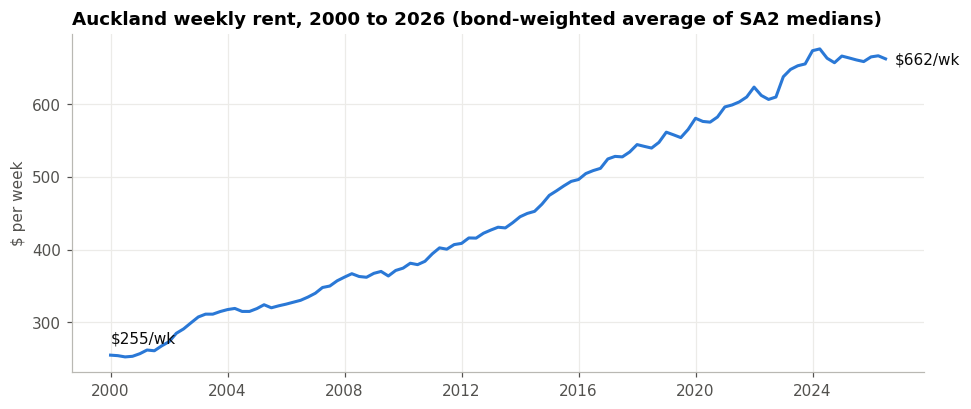

Annual change in average rent, last 8 years (%):
quarter
2019-12-31    3.0
2020-12-31    3.4
2021-12-31    4.0
2022-12-31    1.8
2023-12-31    5.8
2024-12-31    2.9
2025-12-31   -0.8
2026-12-31    0.4
Freq: YE-DEC


In [7]:
# STEP 5: RENT TREND AND SPREAD
# Auckland-wide line = bond-weighted average of SA2 median rents (an approximation, not MBIE's own regional median)
ts = rent_ts[rent_ts.quarter >= '2000-01-01'].dropna(subset=['median_rent'])
akl = ts.groupby('quarter').apply(lambda d: np.average(d.median_rent, weights=d.active_bonds), include_groups=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(akl.index, akl.values, color=BLUE, lw=2)
last = akl.index[-1]
ax.annotate(f'${akl.iloc[-1]:.0f}/wk', (last, akl.iloc[-1]), xytext=(6, 0), textcoords='offset points', color=INK, va='center')
ax.annotate(f'${akl.loc["2000"].iloc[0]:.0f}/wk', (akl.index[0], akl.iloc[0]), xytext=(0, 8), textcoords='offset points', color=INK)
ax.set(title='Auckland weekly rent, 2000 to 2026 (bond-weighted average of SA2 medians)', ylabel='$ per week')
fig.savefig(VIZ / '01_rent_trend.png'); plt.show()

yoy = akl.resample('YE').mean().pct_change().mul(100).round(1)
print('Annual change in average rent, last 8 years (%):'); print(yoy.tail(8).to_string())

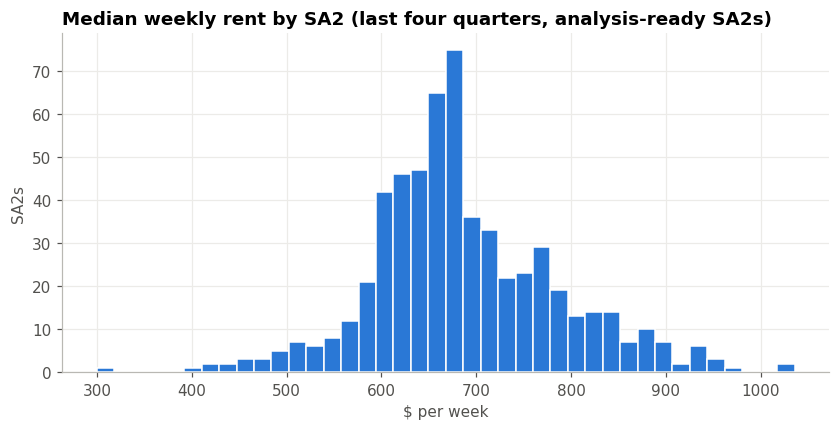

Cheapest and dearest rents:


,sa2_name,median_rent_weekly,active_bonds,rent_change_5y_pct,flag_borrowed_rent
542,Grafton,300.0,516.0,-38.6,False
620,The Strand,403.0,540.0,-25.3,False
631,Symonds Street North West,415.0,1254.0,15.3,False
623,Hobson Ridge South,427.5,570.0,10.0,False
77,Onetangi,430.8,72.0,-25.0,False
13,Waitākere Ranges South,436.7,60.0,-16.3,False
157,Remuera Waitaramoa,1035.8,318.0,17.4,False
529,Westmere North,1023.8,114.0,14.4,False
151,Campbells Bay,969.5,177.0,23.4,False
153,Glendowie North,956.2,216.0,24.2,False


In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(ready.median_rent_weekly.dropna(), bins=40, color=BLUE, edgecolor='white', linewidth=1)
ax.set(title='Median weekly rent by SA2 (last four quarters, analysis-ready SA2s)', xlabel='$ per week', ylabel='SA2s')
fig.savefig(VIZ / '01_rent_distribution.png'); plt.show()
c3 = ['sa2_name', 'median_rent_weekly', 'active_bonds', 'rent_change_5y_pct', 'flag_borrowed_rent']
print('Cheapest and dearest rents:')
pd.concat([ready.nsmallest(6, 'median_rent_weekly')[c3], ready.nlargest(6, 'median_rent_weekly')[c3]]).round(1)

### Step 6: Gross rental yield

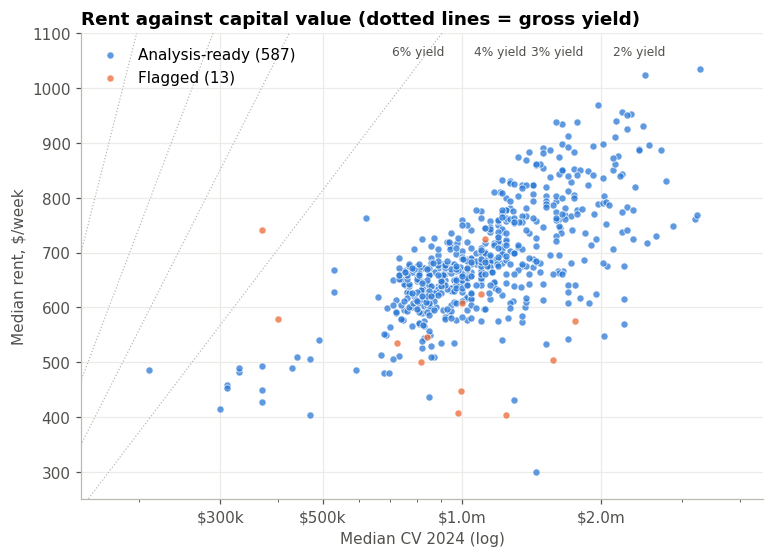

Median gross yield (analysis-ready): 3.25%
Highest yields: inner-city apartments (low CV per unit), not hidden bargains


,sa2_name,median_cv_2024,median_rent_weekly,gross_yield_pct
611,Auckland-University,210000.0,485.25,12.02
625,Symonds Street West,330000.0,490.00,7.72
628,Symonds Street East,310000.0,458.25,7.69
632,Hobson Ridge Central,310000.0,452.50,7.59
622,Queen Street,330000.0,481.25,7.58
631,Symonds Street North West,300000.0,415.00,7.19
629,Anzac Avenue,370000.0,492.50,6.92
245,Quay Street-Customs Street,530000.0,668.25,6.56
630,College Hill,620000.0,763.25,6.40
619,Queen Street South West,370000.0,448.75,6.31


In [9]:
# STEP 6: GROSS YIELD = weekly rent x 52 / median CV (indicative: all-dwelling rent over all-property CV)
fig, ax = plt.subplots(figsize=(8, 5.5))
y = m.dropna(subset=['gross_yield_pct'])
for sub, colour, label in [(y[y.analysis_ready], BLUE, 'Analysis-ready'), (y[~y.analysis_ready], ORANGE, 'Flagged')]:
    ax.scatter(sub.median_cv_2024, sub.median_rent_weekly, s=22, color=colour, alpha=0.75,
               edgecolor='white', linewidth=0.6, label=f'{label} ({len(sub)})')
for pct in [2, 3, 4, 6]:   # iso-yield guide lines
    xs = np.array([1e5, 5e6]); ax.plot(xs, xs * pct / 100 / 52, color=GREY, lw=0.8, ls=':')
    ax.annotate(f'{pct}% yield', (1060 * 52 / (pct / 100), 1060), color=MUTED, fontsize=8, ha='right')
cv_axis(ax, 1e5, 5e6); ax.set_xlim(1.5e5, 4.5e6); ax.set_ylim(250, 1100)
ax.set(title='Rent against capital value (dotted lines = gross yield)', xlabel='Median CV 2024 (log)', ylabel='Median rent, $/week')
ax.legend(frameon=False, loc='upper left')
fig.savefig(VIZ / '01_yield_scatter.png'); plt.show()

c4 = ['sa2_name', 'median_cv_2024', 'median_rent_weekly', 'gross_yield_pct']
print(f'Median gross yield (analysis-ready): {ready.gross_yield_pct.median():.2f}%')
print('Highest yields: inner-city apartments (low CV per unit), not hidden bargains')
ready.nlargest(10, 'gross_yield_pct')[c4].round(2)

### Step 7: Crime rates with and without flagged SA2s

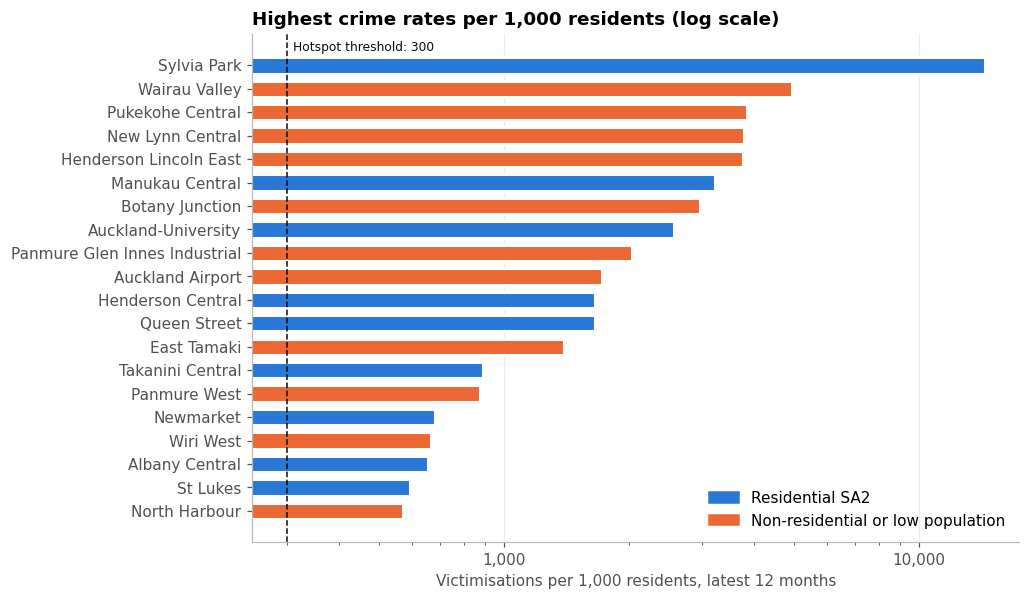

,All SA2s,Analysis-ready,"Analysis-ready, no hotspots"
count,619.0,599.0,586.0
mean,131.4,87.3,41.7
std,710.1,619.9,43.1
min,0.0,0.0,0.0
25%,16.2,16.0,15.8
50%,29.7,29.2,28.4
75%,53.3,50.0,47.2
max,14393.2,14393.2,271.4


In [10]:
# STEP 7: CRIME PER 1,000 RESIDENTS
top = m.dropna(subset=['crime_per_1000_residents']).nlargest(20, 'crime_per_1000_residents').iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.sa2_name, top.crime_per_1000_residents, height=0.7,
        color=np.where(top.analysis_ready, BLUE, ORANGE), edgecolor='white', linewidth=2)
ax.axvline(300, color=INK, lw=1, ls='--'); ax.annotate('Hotspot threshold: 300', (300, len(top) - 0.4), xytext=(4, 0), textcoords='offset points', fontsize=8, color=INK)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.legend(handles=[Patch(color=BLUE, label='Residential SA2'), Patch(color=ORANGE, label='Non-residential or low population')], frameon=False, loc='lower right')
ax.set(title='Highest crime rates per 1,000 residents (log scale)', xlabel='Victimisations per 1,000 residents, latest 12 months')
ax.grid(axis='y', visible=False)
fig.savefig(VIZ / '01_crime_top20.png'); plt.show()

comparable = ready[~ready.flag_crime_hotspot]
both = pd.DataFrame({'All SA2s': m.crime_per_1000_residents.describe(), 'Analysis-ready': ready.crime_per_1000_residents.describe(),
                     'Analysis-ready, no hotspots': comparable.crime_per_1000_residents.describe()})
both.round(1)

**Reading this:** crime counts follow visitors, not residents. Shopping centres, the CBD and the airport rank highest
because their resident base is small. For the dashboard, show crime *counts* and *type mix* alongside the rate,
and keep flagged SA2s out of any "safest/least safe" ranking.

### Step 8: How the measures relate

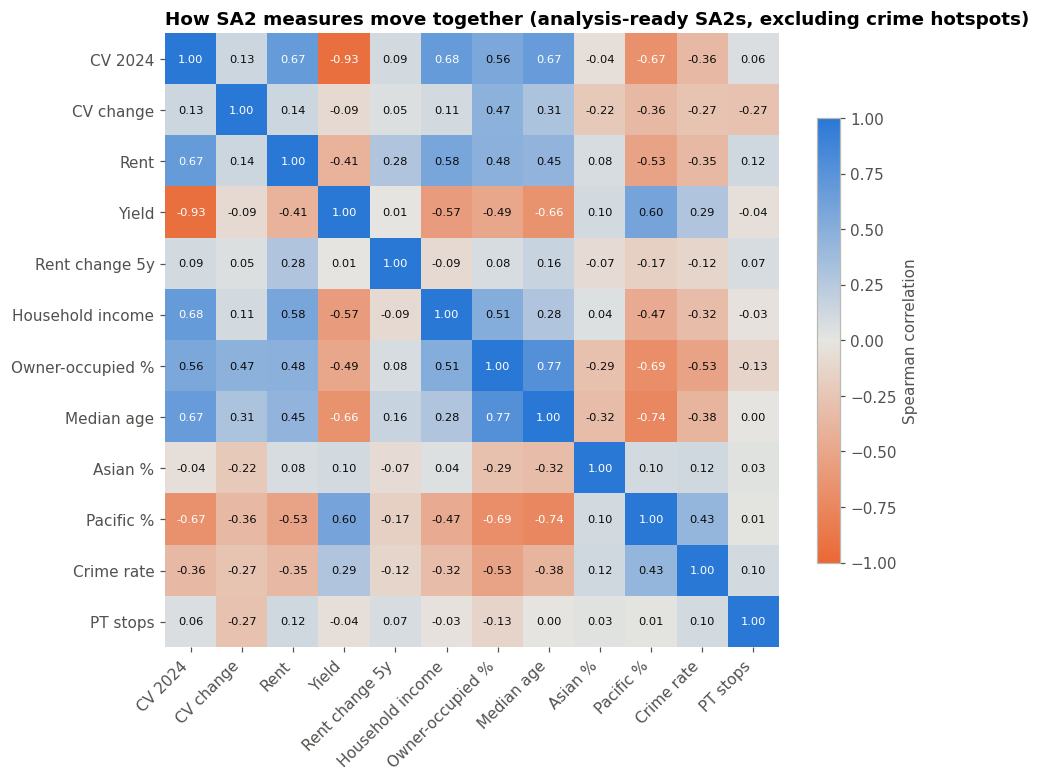

Strongest relationships with CV 2024:


Yield              -0.93
Household income    0.68
Rent                0.67
Pacific %          -0.67
Median age          0.67
Owner-occupied %    0.56
Crime rate         -0.36
CV change           0.13
Rent change 5y      0.09
PT stops            0.06
Asian %            -0.04
Name: CV 2024, dtype: float64

In [11]:
# STEP 8: CORRELATION (Spearman: rank-based, robust to the skew seen above)
vars_ = {'median_cv_2024': 'CV 2024', 'cv_change_2021_2024_pct': 'CV change', 'median_rent_weekly': 'Rent',
         'gross_yield_pct': 'Yield', 'rent_change_5y_pct': 'Rent change 5y', 'median_household_income': 'Household income',
         'pct_owner_occupied': 'Owner-occupied %', 'median_age': 'Median age', 'pct_asian': 'Asian %',
         'pct_pacific': 'Pacific %', 'crime_per_1000_residents': 'Crime rate', 'pt_stops': 'PT stops'}
corr = ready[~ready.flag_crime_hotspot][list(vars_)].rename(columns=vars_).corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right'); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iat[i, j]:.2f}', ha='center', va='center', fontsize=7.5,
                color='white' if abs(corr.iat[i, j]) > 0.6 else INK)
ax.grid(False); ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.7, label='Spearman correlation')
ax.set_title('How SA2 measures move together (analysis-ready SA2s, excluding crime hotspots)')
fig.savefig(VIZ / '01_correlation.png'); plt.show()

print('Strongest relationships with CV 2024:')
corr['CV 2024'].drop('CV 2024').sort_values(key=abs, ascending=False).round(2)

### Step 9: Save outputs

In [12]:
# STEP 9: SAVE OUTPUTS
out = CLEAN / 'master_flagged.csv'
m.round(2).to_csv(out, index=False)
check = pd.read_csv(out)
assert len(check) == 633 and check.sa2_code.is_unique and set(flags) <= set(check.columns)
print(f'Saved {out} ({check.shape[0]} rows, {check.shape[1]} columns)')
print('Charts:', ', '.join(sorted(p.name for p in VIZ.glob('01_*.png'))))

Saved data\clean\master_flagged.csv (633 rows, 62 columns)
Charts: 01_correlation.png, 01_crime_top20.png, 01_cv_distribution.png, 01_cv_maps.png, 01_rent_distribution.png, 01_rent_trend.png, 01_yield_scatter.png


# File 1: Data Exploration & Quality - Summary

## What we did
Loaded the cleaned SA2 dataset (633 SA2s, 1.66 million residents), checked coverage, looked at every main measure
for outliers, and built data-quality flags. The result is `data/clean/master_flagged.csv`, which later notebooks and the
dashboard should read instead of the raw master file.

## Problems found and how they were handled
| Problem | Evidence | Handling |
|---|---|---|
| CV medians driven by non-housing land | Middlemore \$31m (hospital, 3 dwellings), Mount Wellington Industrial \$5.1m | `flag_non_residential`: more than 2 rating units per dwelling, or fewer than 30 dwellings (34 SA2s, mostly industrial areas, harbours and ocean) |
| Near-empty SA2s | 14 SA2s under 100 residents | `flag_low_population` |
| Per-resident crime rates distorted by visitors | Sylvia Park 14,393 per 1,000 (117 residents, a mall) | `flag_crime_hotspot`: over 300 per 1,000 (27 SA2s). Kept for CV and rent, left out of crime rankings |
| Shared rent figures | 142 SA2s share one MBIE (2018) source SA2's rent with another SA2 (`rent_source_sa2`) | `flag_borrowed_rent`, shown as a label only |

**599 SA2s are analysis-ready and hold 99.3% of residents**, so the flags remove noise without losing coverage.

## Key findings
1. **Capital values fell between valuations.** The median SA2 dropped 8.6% from 2021 to 2024, and only 56 of 599 rose,
   mostly rural fringe areas (Ramarama, Bombay Hills, Matakana). 2021 was valued close to the market peak.
   *Benchmark:* Auckland Council's 2024 revaluation release gave an average residential movement of about −9% (cross-checked in the 17 Nov 2026 review; not re-checked here).
2. **Rent kept rising and has only recently flattened.** Average weekly rent went from about \$255 in 2000 to \$662 in 2026.
   It grew about 2-6% a year up to 2024, then went flat (-0.8% in 2025, +0.4% so far in 2026).
3. **Gross yield is mostly the inverse of price.** Yield and CV have a rank correlation of -0.93, and the median yield is 3.25%.
   The yields above 6% are all inner-city apartment SA2s (Symonds Street, Queen Street, Hobson Ridge), where a small unit's CV is low.
   They are not hidden bargains.
4. **Price follows income, age and tenure.** CV correlates with household income (0.68), median age (0.67) and owner-occupation (0.56),
   and is lower where the Pacific share is higher (-0.67). Five-year rent change barely relates to anything (all |r| < 0.3).
5. **Crime is concentrated in town centres.** With hotspots removed, the median is 28 victimisations per 1,000 residents in the latest 12 months
   and the highest is 271.

## What this means for the dashboard
- Use the flags: grey out or hatch flagged SA2s on maps, and exclude them from rankings.
- Show yield together with CV and dwelling type, not as a stand-alone "best investment" ranking.
- The rent time series is the only real history (2000-2026). Rent trends should be a main page; CV has only two points in time.
- Show crime as counts and type mix next to the rate, with hotspots labelled.

## Limitations
- The flag thresholds (2 units per dwelling, 30 dwellings, 300 per 1,000) are judgement calls, picked from the distributions above.
- The Auckland-wide rent line is a bond-weighted average of SA2 medians, not MBIE's own regional median.
- CVs are council valuations, not sale prices, and still mix housing types inside an SA2.

## Next notebooks (suggested)
- **File 2: Rental analysis**: rent trends by area, rent growth, affordability against census income.
- **File 3: Area profiles**: demographics and amenities, and how they relate to rent and CV.
- **File 4: Risk & value screen**: combine CV, yield, rent growth and crime, using only analysis-ready SA2s.
